# Experiment: time-reversal regimes under slow nuisances, autocorrelation, noise and nonlinear mixing

The regime signal is the one of `experiment_reversal.ipynb`: two independent channels carry an asymmetric wave $\sin\phi + b\cos 3\phi$, and the regime (K = 4) sets the direction in which each channel's phase runs. Mean, variance, every autocovariance and every odd moment are the same in all regimes; only the fourth-order time asymmetry $E[x_t^3 x_{t+l} - x_t x_{t+l}^3]$ differs.

This version buries it under:
1. **Slow regime-independent factors:** two mean-reverting trends (timescale ~1000 samples) and two slow narrowband oscillations (periods 200 and 500 samples), each with the variance of a regime channel.
2. **Autocorrelation:** first-order low-pass sensor dynamics per channel (random coefficient up to 0.6).
3. **Noise:** white (σ = 0.5) plus coloured AR noise (σ = 0.5, correlation time 16 samples).
4. **A nonlinear projection:** a random up-projection of the 6 channels to D = 8, then two invertible affine coupling layers (nonlinear mixing across channels).

The slow factors and the Gaussian noise are time-reversible, so before the nonlinear step every regime still has identical second-order statistics. The nonlinear mixing can move part of the fourth-order asymmetry into second-order cross-covariances; the raw baselines measure how much.

**Pre-run audit** (4 test series, best of GMM / HMM / AR-HMM / temporal excess): every raw baseline stays near chance, including the hand-crafted asymmetry feature `raw_asym` (0.46, versus 0.97 without the nuisances) and the bispectrum (0.40). The same asymmetry feature computed on the clean regime signal (`oracle_clean`) reaches 0.97, so the regime is in the data but no fixed window statistic we have recovers it.

**Protocol** as in the other experiments: every feature learner (including the untrained `jepa_shared` control), every registered detector, sample-level scoring; supervised probes are diagnostics only.

**Cost.** About 1.5–2 h locally. `CPBENCH_QUICK=1` is a plumbing check whose numbers mean nothing.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cpbench import Benchmark, make_learner, make_detector, viz
from cpbench.data import Dataset
from cpbench.features import LEARNERS
from cpbench.detectors import DETECTORS
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", message="FastICA did not converge")

QUICK = os.environ.get("CPBENCH_QUICK") == "1"     # ✏️ True: plumbing check only (20 steps, tiny splits)
RUNS = "cpbench_runs_reversal_hard" + ("_quick" if QUICK else "")
OUT = "cpbench_results/reversal_hard_experiment" + ("_quick" if QUICK else "") + ".csv"
print("QUICK" if QUICK else "full run", "->", RUNS)

full run -> cpbench_runs_reversal_hard


## 1. Dataset

Regime source `reversal` (cpbench/data/structured.py); nuisance sources `trend` and `oscillator` with regime-independent parameters; then the corruption chain in order. With W = 64 a window holds 2–3 periods of each regime wave and a small piece of each slow factor. Segments last 640 samples on average, about 10 windows.

In [2]:
# ✏️ the experiment's dataset
def hard_dataset(quick=False):
    return dict(
        regime=dict(type="markov", K=4, dwell=640),
        sources=[dict(type="reversal", d=2, freq=[0.031, 0.047], b=0.5, diff=0.002),          # the regime signal
                 dict(type="trend", d=2, sigma=0.03, kappa=0.001),                              # slow mean-reverting trends
                 dict(type="oscillator", d=2, freq=dict(channels=[0.002, 0.005]), damp=0.999, sigma=1.0)],     # slow oscillations
        transforms=[dict(type="lowpass", max_alpha=0.6),                                        # autocorrelation (sensor dynamics)
                    dict(type="noise", sigma=0.5),                                              # white noise
                    dict(type="noise", sigma=0.5, timescale=16),                                # coloured (AR) noise
                    dict(type="project", D=8),                                                  # up-projection ...
                    dict(type="couplings", n=2, strength=0.5)],                                 # ... made nonlinear
        seed=0,
        splits=dict(test=[2, 4000], val=[2, 4000]) if quick else dict(test=[8, 32000], val=[4, 16000]))

DATASET = hard_dataset(QUICK)
W, GAP = 64, 64                         # ✏️ window and context-target gap (samples)
ds = Dataset(DATASET)
data = ds.test_set()
print(ds.info.id)
print(f"K={ds.K}, D={ds.D}, test split {data['obs'].shape}")

markov(dwell=640)|reversal|trend(d=2,kappa=0.001,sigma=0.03)+oscillator(d=2,damp=0.999,freq={channels:[0.002,0.005]})|lowpass>noise>noise(timescale=16)>project(D=8)>couplings(n=2,strength=0.5)#282b2015
K=4, D=8, test split (8, 32000, 8)


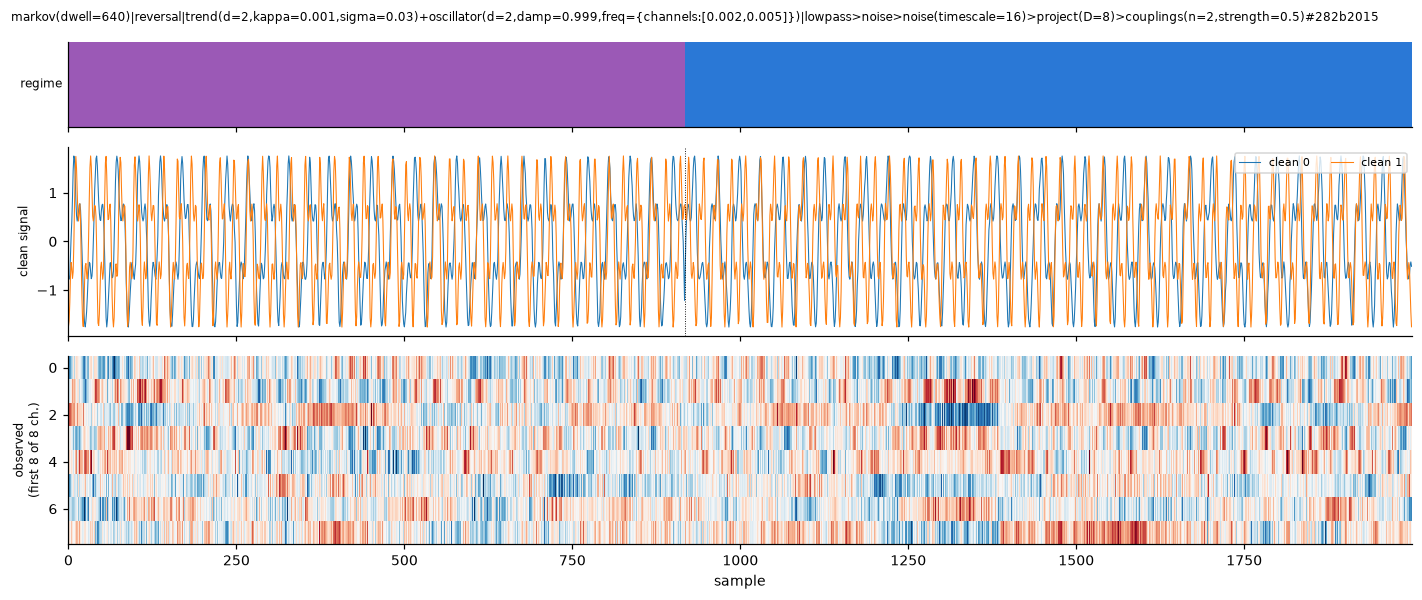

In [3]:
viz.plot_dataset(ds, data, series=0, n=2000)

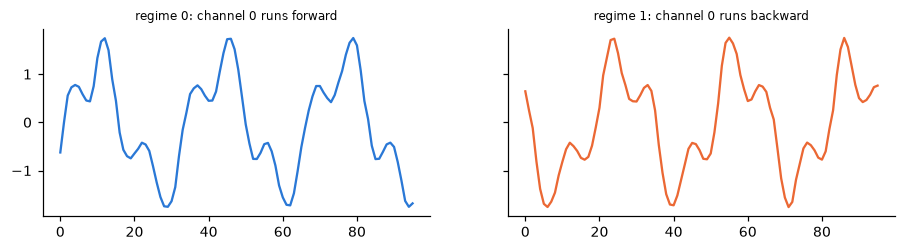

In [4]:
# the waveform of one clean channel in a forward and a backward regime
x, S = data["clean"][..., 0], data["S_s"]
fig, ax = plt.subplots(1, 2, figsize=(10, 2.2), sharey=True)
for a, k in zip(ax, (0, 1)):
    r, t = np.argwhere(S[:, 200:-200] == k)[100]; t += 200
    a.plot(np.arange(96), x[r, t:t + 96], color=viz.COLORS[k]); a.set_title(f"regime {k}: channel 0 runs {'backward' if k & 1 else 'forward'}", fontsize=8)
plt.show()

In [5]:
# check: per-regime statistics of the observations, pooled over 128-sample stretches inside one regime (channel 0 and
# the pair 0-1).  Before the nonlinear mixing everything up to third order agrees across regimes; differences here
# show what the nonlinear projection leaks into low-order statistics.
def regime_stats(x, S, k, L=128):
    segs = np.stack([x[r, t:t + L] for r in range(len(x)) for t in range(0, x.shape[1] - L, L) if (S[r, t:t + L] == k).all()])
    a, b = segs[..., 0], segs[..., 1]
    lag = lambda f, l: float(np.mean(f(a[:, :L - l], a[:, l:])))
    return {"mean": a.mean(), "var": a.var(), "kurtosis": float(((a - a.mean()) ** 4).mean() / a.var() ** 2 - 3),
            **{f"autocov l={l}": lag(lambda u, v: u * v, l) for l in (1, 5, 10)},
            "crosscov 0-1 l=+5": float(np.mean(a[:, :-5] * b[:, 5:])), "crosscov 0-1 l=-5": float(np.mean(a[:, 5:] * b[:, :-5])),
            "skewness": float(((a - a.mean()) ** 3).mean() / a.var() ** 1.5),
            **{f"3rd-order asym l={l}": lag(lambda u, v: u ** 2 * v - u * v ** 2, l) for l in (3, 8)},
            **{f"4th-order asym l={l}": lag(lambda u, v: u ** 3 * v - u * v ** 3, l) for l in (3, 8)}}
x = data["obs"].astype(float)
pd.DataFrame({f"regime {k}": regime_stats(x, data["S_s"], k) for k in range(ds.K)}).round(3)

,regime 0,regime 1,regime 2,regime 3
mean,-0.008,0.042,0.027,0.007
var,1.010,0.976,0.988,0.999
kurtosis,-0.073,-0.107,-0.102,-0.174
autocov l=1,0.777,0.741,0.759,0.761
autocov l=5,0.431,0.397,0.414,0.409
autocov l=10,0.045,0.010,0.021,0.022
crosscov 0-1 l=+5,0.011,0.018,0.002,-0.003
crosscov 0-1 l=-5,0.018,0.015,0.005,-0.001
skewness,0.023,-0.014,0.035,0.014
3rd-order asym l=3,0.001,-0.001,0.002,0.002


## 2. Feature learners and detectors

All registered feature learners are used, except the generic bases (`raw`, `oracle`, `jepa`), which their presets already cover, `oracle_hidden`, which needs a hidden state this dataset does not have.
- Every learner uses the same window W.
- The learners trained on (context, target) pairs also get the gap.
- `oracle_clean` computes the fourth-order asymmetry feature of the noise-free signal: a ceiling, not a competitor. Its default statistic (mean, variance, …), like the spectrum, is identical in every regime here by construction.
- **Control:** `jepa_shared` with `steps=0`, a randomly initialised encoder. A trained learner only counts if it beats this control.

Every registered detector runs with its default parameters, which the ✏️ cell can override. The defaults suit sequences of window features (T = 500 windows per test series here).

The raw baselines × detectors are the classic methods. Here even `raw_asym`, built for the clean design, is expected near chance (pre-run audit: 0.46).

In [6]:
SKIP = {"raw", "oracle", "jepa", "oracle_hidden"}
if ds.D == 1:
    SKIP.add("raw_lagcov")              # lead-lag between channels: undefined on one channel
print("feature learners:", [n for n in LEARNERS.available() if n not in SKIP])
print("detectors:       ", DETECTORS.available())

feature learners: ['ae', 'ae_pred', 'bvae4', 'cpc', 'jepa_mlp_separate', 'jepa_mlp_shared', 'jepa_separate', 'jepa_separate_full', 'jepa_shared', 'oracle_clean', 'raw_asym', 'raw_bispec', 'raw_coskew', 'raw_cov', 'raw_flat', 'raw_lagcov', 'raw_mean', 'raw_spectra', 'raw_stats', 'ts2vec', 'vae', 'vae_pred']
detectors:        ['arhmm', 'bocpd', 'contrast', 'cpdmd', 'dmd_error', 'gmm', 'hmm', 'mmd', 'temporal_excess']


In [7]:
# ✏️ training settings (workers / device / logging do not change the result)
STEPS = 20 if QUICK else 3000
TRAIN = dict(steps=STEPS, batch=128, workers=0 if QUICK else 1, eval_every=max(STEPS // 4, 5), warmup=min(1000, STEPS))

def learner(name, **extra):
    defaults = LEARNERS.defaults(name)
    p = dict(window=W)
    if "gap" in defaults:
        p["gap"] = GAP
    if "steps" in defaults:
        p.update(TRAIN)
    if name == "oracle_clean":
        p["feature"] = "asym"            # the regimes differ only in fourth-order time asymmetry
    return make_learner(name, **{**p, **extra})

FEATURES = [learner(n) for n in LEARNERS.available() if n not in SKIP]
FEATURES.append(learner("jepa_shared", steps=0))   # control: untrained (random) encoder
FIXED = [f for f in FEATURES if not f.trainable]
LEARNT = [f for f in FEATURES if f.trainable]

# ✏️ detectors: every registered one, with optional parameter overrides
OVERRIDES = {}                          # e.g. {"bocpd": dict(hazard=0.1), "cpdmd": dict(w=40, d=10, r=4)}
DETS = [dict(type=n, **OVERRIDES.get(n, {})) for n in DETECTORS.available()]
print(len(FIXED), "fixed and", len(LEARNT), "trained feature learners;", len(DETS), "detectors")

10 fixed and 13 trained feature learners; 9 detectors


## 3. Fit, extract features, detect

The fixed learners run first. Each trained learner is then fitted, or loaded if `RUNS` already holds it, and every detector runs on its features. Results go to `OUT` after each learner, so an interrupted run keeps what it finished.

In [8]:
bench = Benchmark(ds, detectors=DETS, out=RUNS, log=lambda *a: None)
results = []
for f in FIXED + LEARNT:
    results.append(bench.run(f))
    pd.concat(results, ignore_index=True).to_csv(OUT, index=False)
    r = results[-1]; r = r[(r.view == "features") & r.metric.isin(["acc", "cp_ap"])]
    print(f"{f.label():<40}", "  ".join(f"{m} max {r[r.metric == m].value.max():.2f}" for m in ("acc", "cp_ap")))
res = pd.concat(results, ignore_index=True)

oracle_clean(window=64, feature=asym)    acc max 0.95  cp_ap max 0.68
raw_asym(window=64)                      acc max 0.46  cp_ap max 0.09
raw_bispec(window=64)                    acc max 0.42  cp_ap max 0.06
raw_coskew(window=64)                    acc max 0.28  cp_ap max 0.04
raw_cov(window=64)                       acc max 0.29  cp_ap max 0.04
raw_flat(window=64)                      acc max 0.29  cp_ap max 0.31
raw_lagcov(window=64)                    acc max 0.29  cp_ap max 0.04
raw_mean(window=64)                      acc max 0.29  cp_ap max 0.04
raw_spectra(window=64)                   acc max 0.29  cp_ap max 0.08
raw_stats(window=64)                     acc max 0.28  cp_ap max 0.04
ae(window=64, gap=64, steps=3000, batch=128) acc max 0.29  cp_ap max 0.33
ae_pred(window=64, gap=64, steps=3000, batch=128) acc max 0.29  cp_ap max 0.34
bvae4(window=64, gap=64, steps=3000, batch=128) acc max 0.30  cp_ap max 0.26
cpc(window=64, gap=64, steps=3000, batch=128) acc max 0.29  cp_ap max 

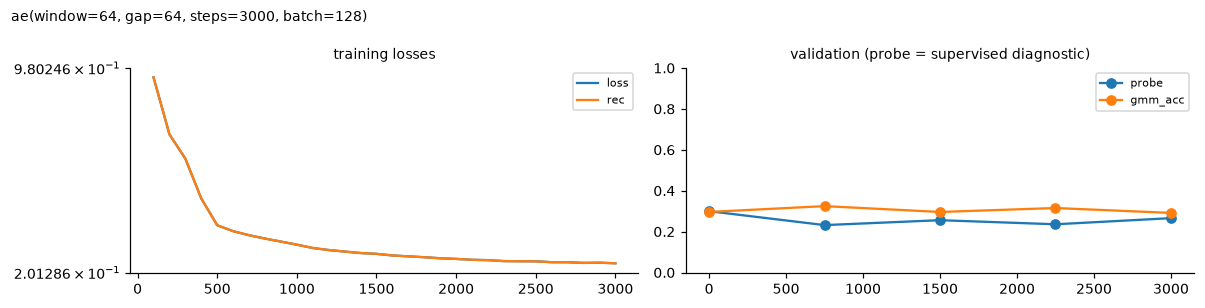

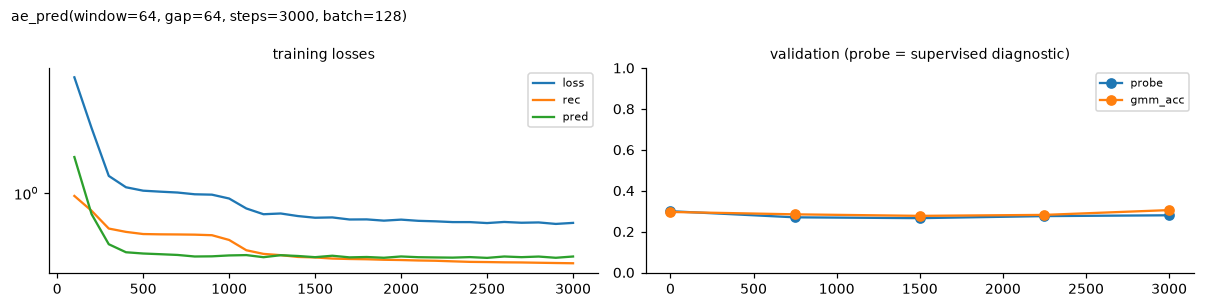

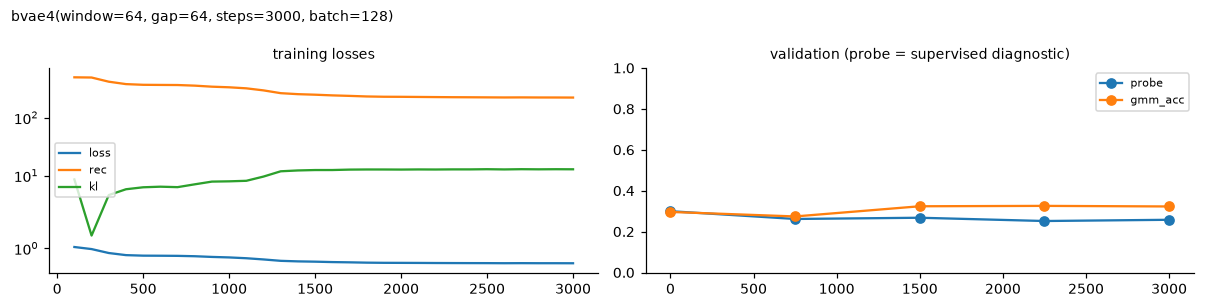

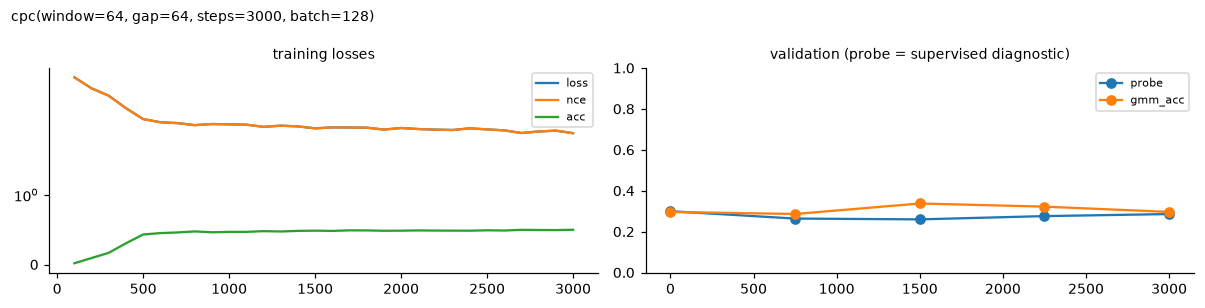

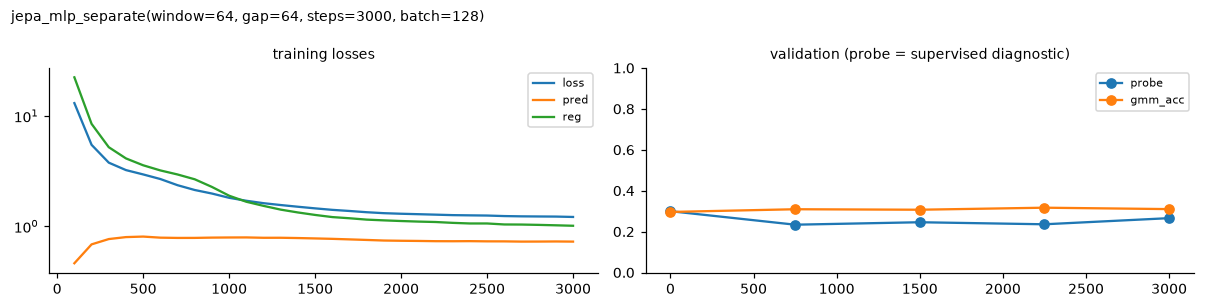

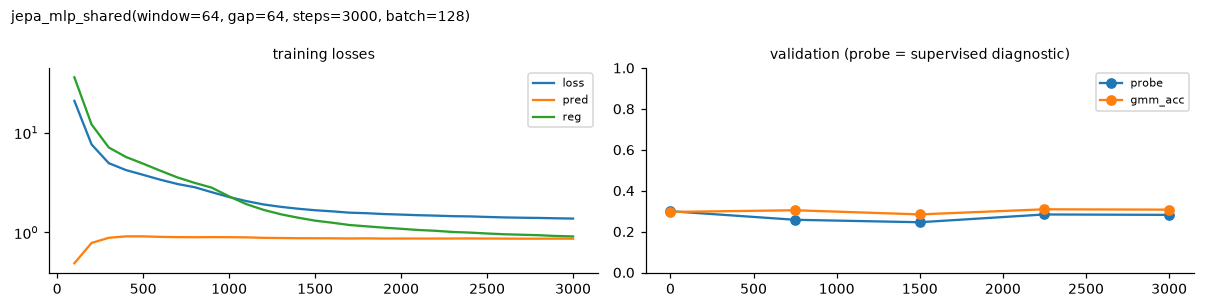

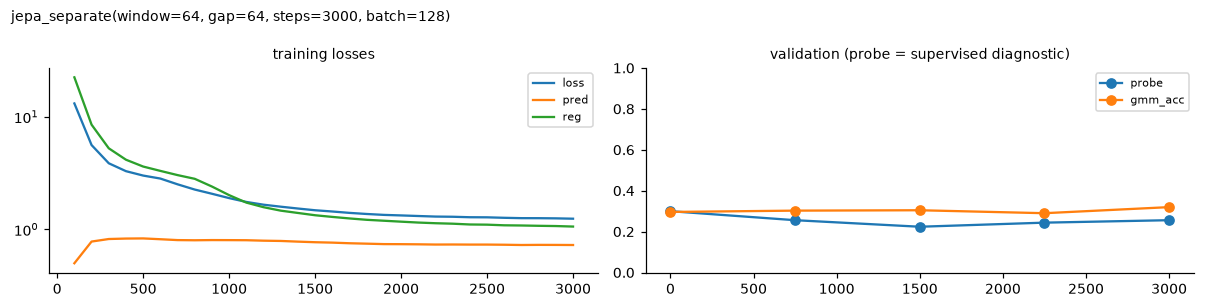

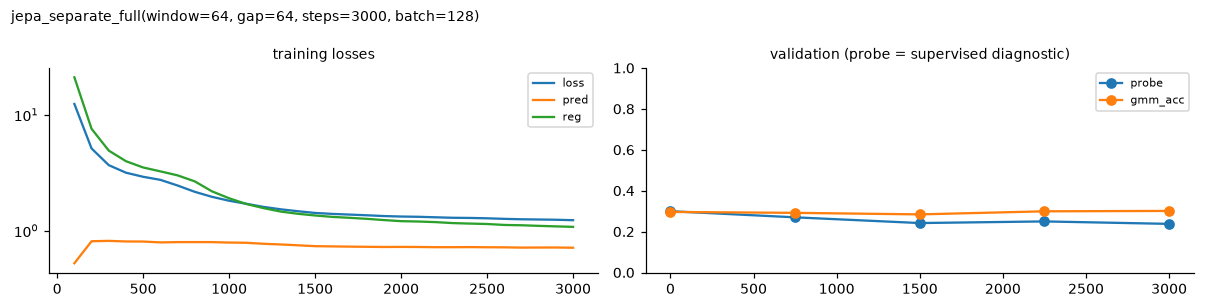

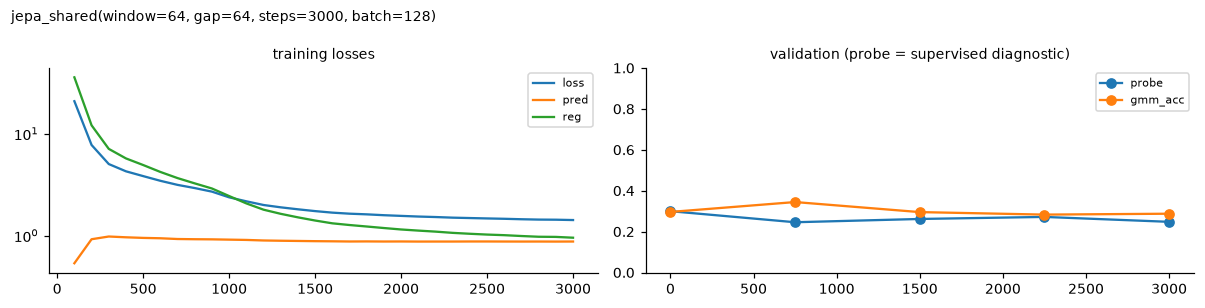

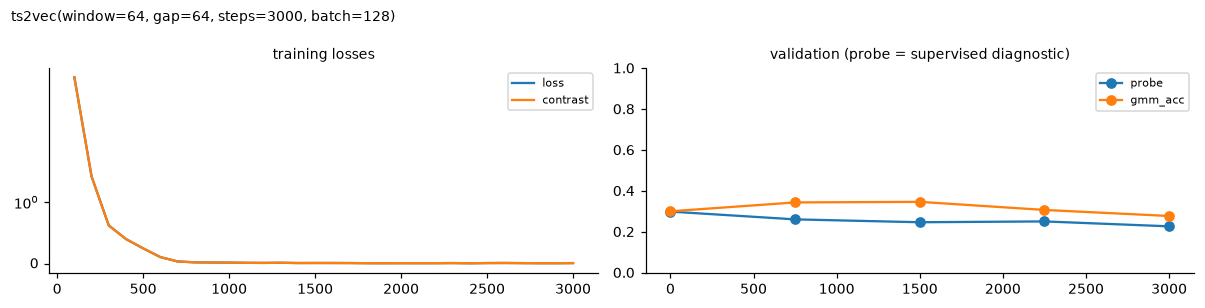

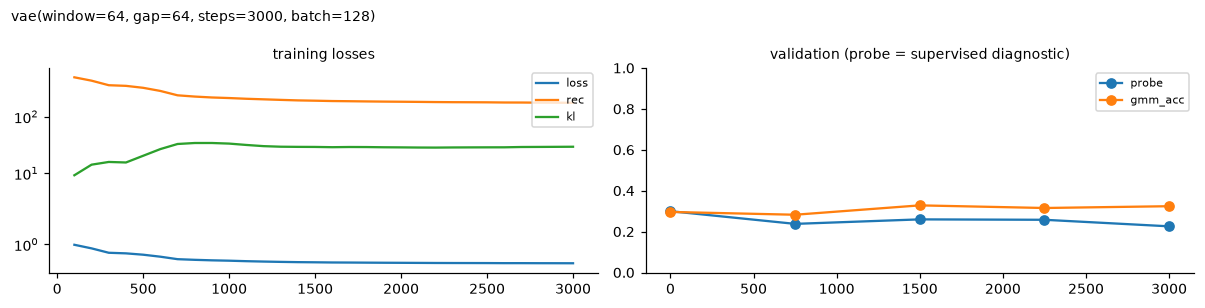

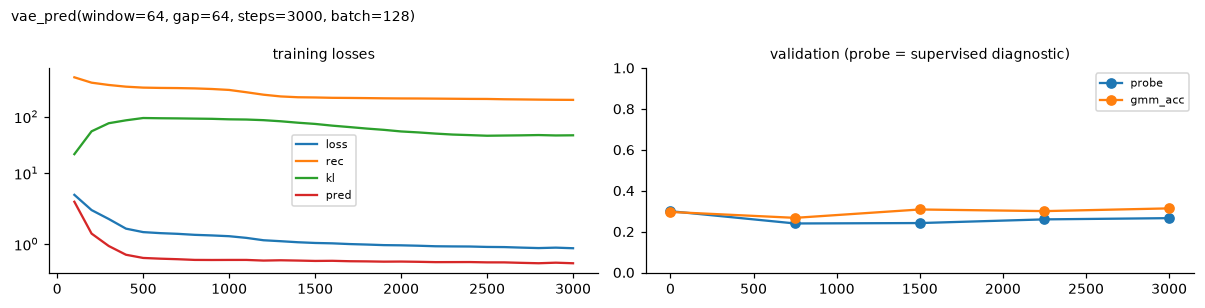

no training log (fixed feature learner?)


In [9]:
# training curves of the trained learners (losses; validation probe and GMM accuracy)
for f in LEARNT:
    viz.plot_training(bench.run_dir(f), title=f.label())

## 4. Results

The heatmaps show every feature learner × detector:
- `acc`: sample-level clustering accuracy after the best label permutation (chance 0.25);
- `cp_ap`: change-point average precision;
- `cp_f1`: F1 at the default threshold, or at the detector's own alarms (CPDMD).

Change-point detectors have no `acc`. Rows are the feature learners and columns the detectors.

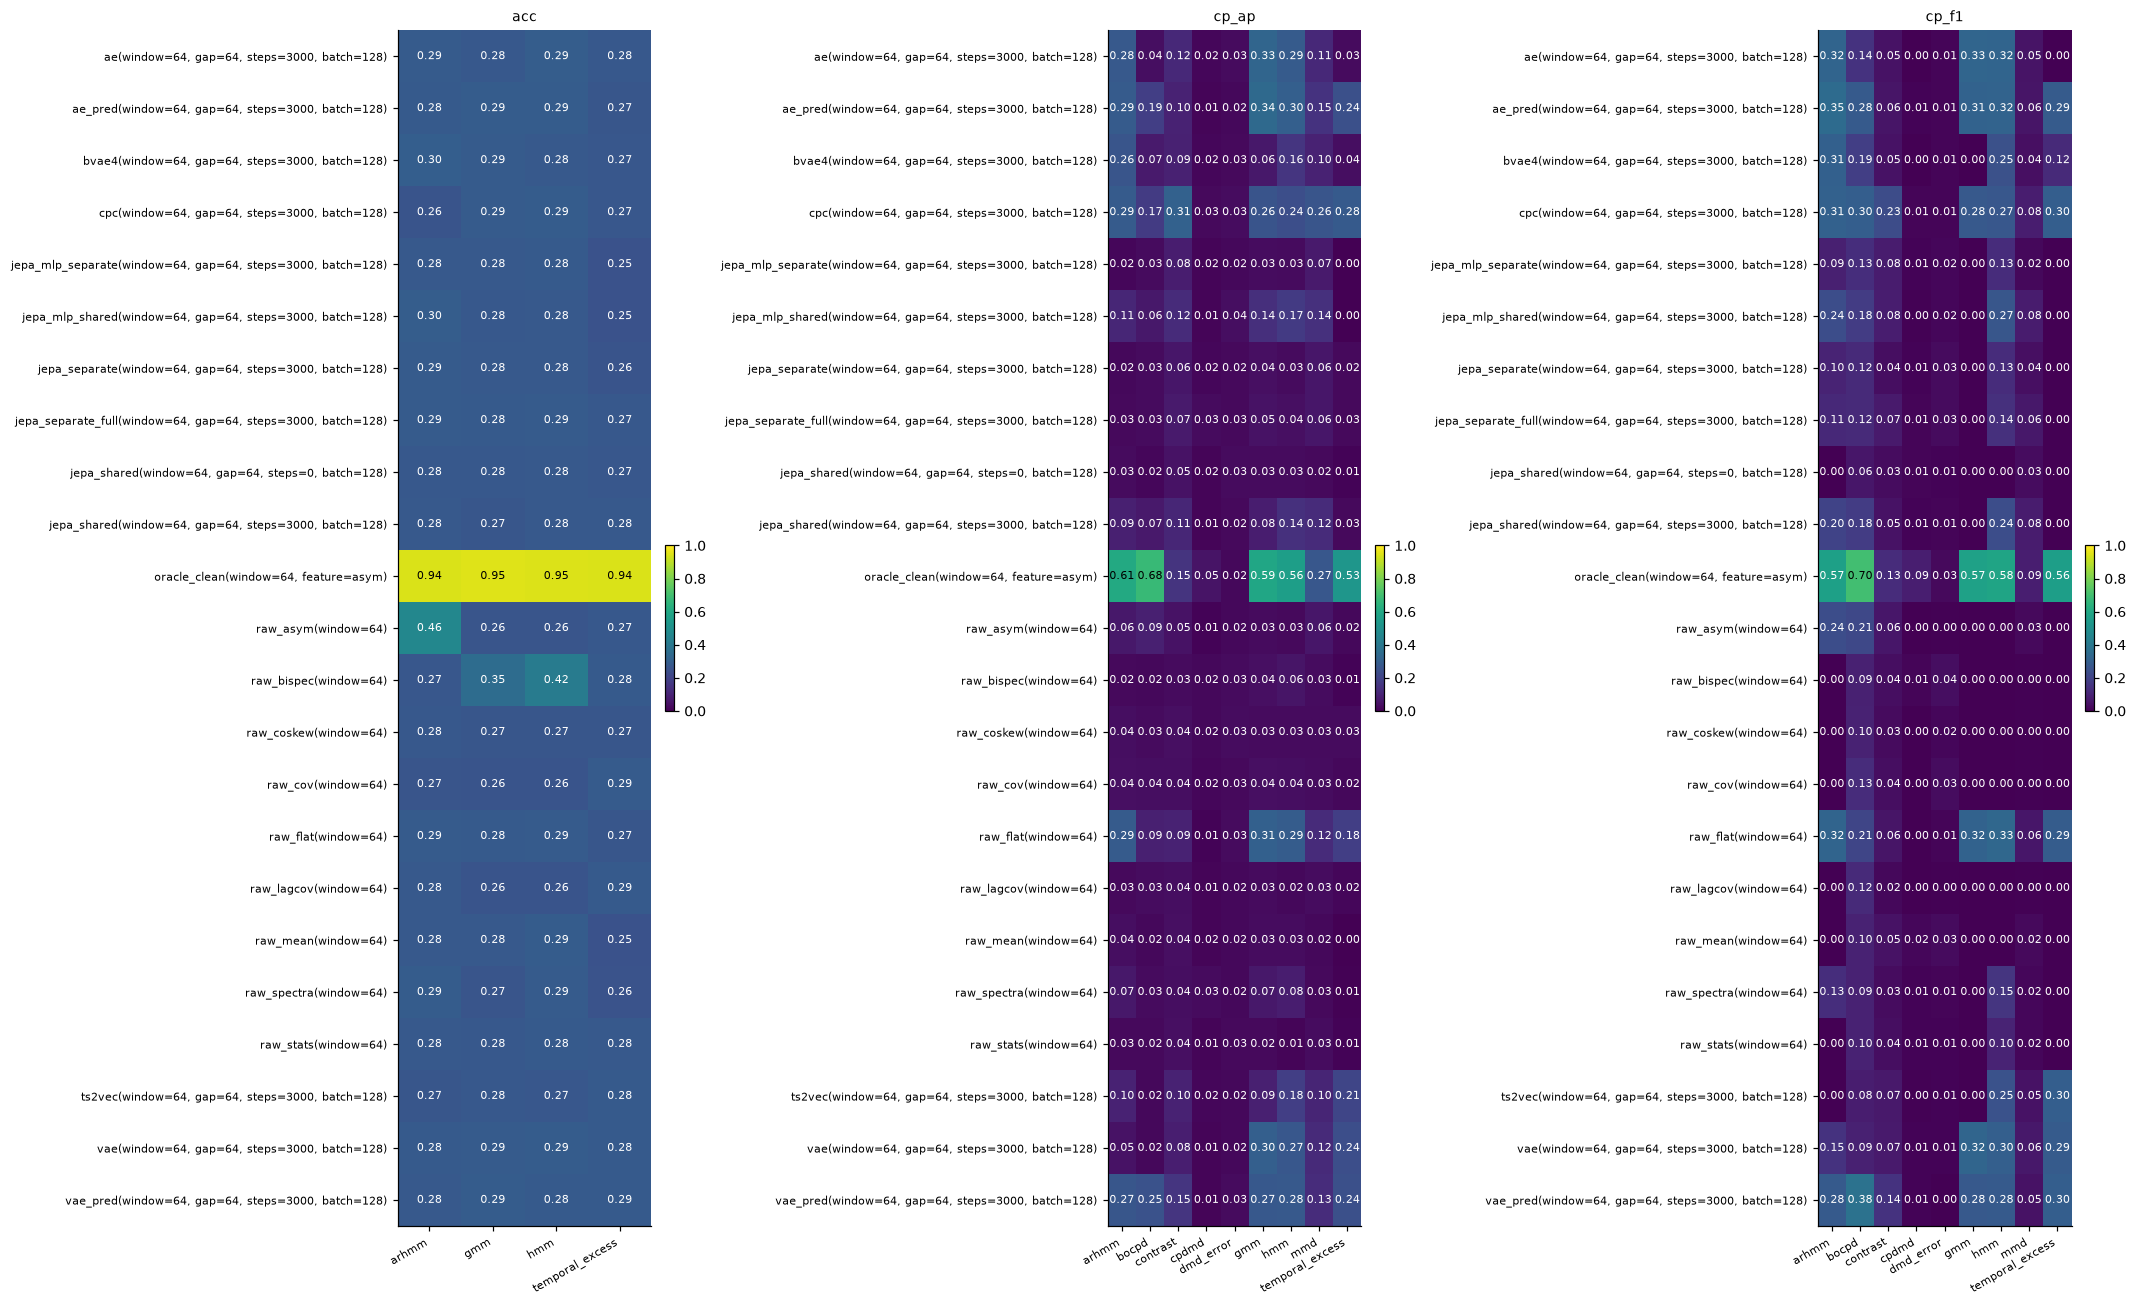

In [10]:
viz.plot_results(res, metrics=("acc", "cp_ap", "cp_f1"))

In [11]:
# best detector per feature learner (clustering accuracy, change-point AP), plus the supervised probe (diagnostic)
f_ = res[res.view == "features"]
best = pd.DataFrame({
    "acc (best clustering detector)": f_[f_.metric == "acc"].groupby("features_label").value.max(),
    "cp_ap (best detector)": f_[f_.metric == "cp_ap"].groupby("features_label").value.max(),
    "linear probe (supervised)": f_[(f_.detector == "probe") & (f_.metric == "probe_linear")].groupby("features_label").value.max(),
})
best.sort_values("acc (best clustering detector)", ascending=False).round(3)

,acc (best clustering detector),cp_ap (best detector),linear probe (supervised)
features_label,,,
"oracle_clean(window=64, feature=asym)",0.952,0.676,0.989
raw_asym(window=64),0.464,0.087,0.563
raw_bispec(window=64),0.417,0.055,0.258
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.298,0.262,0.269
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.295,0.170,0.279
"ae(window=64, gap=64, steps=3000, batch=128)",0.294,0.327,0.273
raw_spectra(window=64),0.293,0.079,0.253
raw_mean(window=64),0.292,0.040,0.251
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.291,0.340,0.267


In [12]:
# full tables
for m in ("acc", "cp_ap", "cp_f1", "cp_covering"):
    t = f_[(f_.metric == m) & (f_.detector != "probe")].pivot_table(index="features_label", columns="detector_label", values="value")
    if len(t):
        print(m); display(t.round(3))

acc


detector_label,arhmm,gmm,hmm,temporal_excess
features_label,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.289,0.277,0.294,0.277
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.285,0.291,0.290,0.269
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.298,0.286,0.281,0.273
"cpc(window=64, gap=64, steps=3000, batch=128)",0.260,0.288,0.290,0.272
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.278,0.279,0.284,0.250
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.295,0.277,0.281,0.250
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.287,0.280,0.281,0.260
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.288,0.282,0.287,0.274
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.275,0.276,0.279,0.272


cp_ap


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.279,0.037,0.116,0.017,0.028,0.327,0.287,0.113,0.027
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.286,0.187,0.098,0.014,0.022,0.340,0.303,0.147,0.243
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.262,0.072,0.092,0.016,0.026,0.063,0.156,0.095,0.037
"cpc(window=64, gap=64, steps=3000, batch=128)",0.286,0.174,0.309,0.025,0.034,0.259,0.241,0.265,0.283
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.019,0.031,0.080,0.016,0.022,0.035,0.028,0.071,0.000
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.108,0.064,0.123,0.015,0.036,0.135,0.170,0.140,0.000
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.023,0.028,0.060,0.016,0.024,0.043,0.028,0.060,0.024
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.026,0.029,0.073,0.028,0.026,0.047,0.042,0.060,0.026
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.031,0.018,0.047,0.015,0.028,0.030,0.029,0.025,0.009


cp_f1


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.321,0.145,0.048,0.000,0.013,0.326,0.322,0.054,0.000
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.350,0.282,0.056,0.009,0.014,0.314,0.320,0.059,0.288
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.306,0.186,0.047,0.000,0.013,0.000,0.247,0.041,0.119
"cpc(window=64, gap=64, steps=3000, batch=128)",0.309,0.299,0.232,0.014,0.013,0.281,0.270,0.082,0.298
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.086,0.132,0.076,0.009,0.017,0.000,0.126,0.022,0.000
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.238,0.177,0.081,0.005,0.018,0.000,0.269,0.077,0.000
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.098,0.117,0.039,0.009,0.029,0.000,0.127,0.039,0.000
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.113,0.119,0.072,0.014,0.030,0.000,0.139,0.064,0.000
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.000,0.060,0.032,0.014,0.009,0.000,0.000,0.033,0.000


cp_covering


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.536,0.462,0.148,0.088,0.174,0.510,0.525,0.114,0.036
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.550,0.530,0.161,0.141,0.121,0.486,0.527,0.117,0.509
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.529,0.488,0.205,0.094,0.160,0.036,0.460,0.099,0.438
"cpc(window=64, gap=64, steps=3000, batch=128)",0.518,0.584,0.275,0.113,0.184,0.465,0.468,0.113,0.514
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.421,0.466,0.216,0.130,0.158,0.036,0.423,0.162,0.036
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.515,0.500,0.207,0.103,0.174,0.036,0.524,0.142,0.036
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.429,0.472,0.186,0.113,0.217,0.036,0.443,0.163,0.036
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.442,0.477,0.215,0.084,0.191,0.036,0.410,0.195,0.036
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.036,0.417,0.214,0.108,0.111,0.036,0.036,0.202,0.036


## 5. Inspecting decisions

Below, every detector's decisions on the trained learner with the best clustering accuracy, against the truth, then the 2-D PCA of a few feature spaces coloured by the true regime.

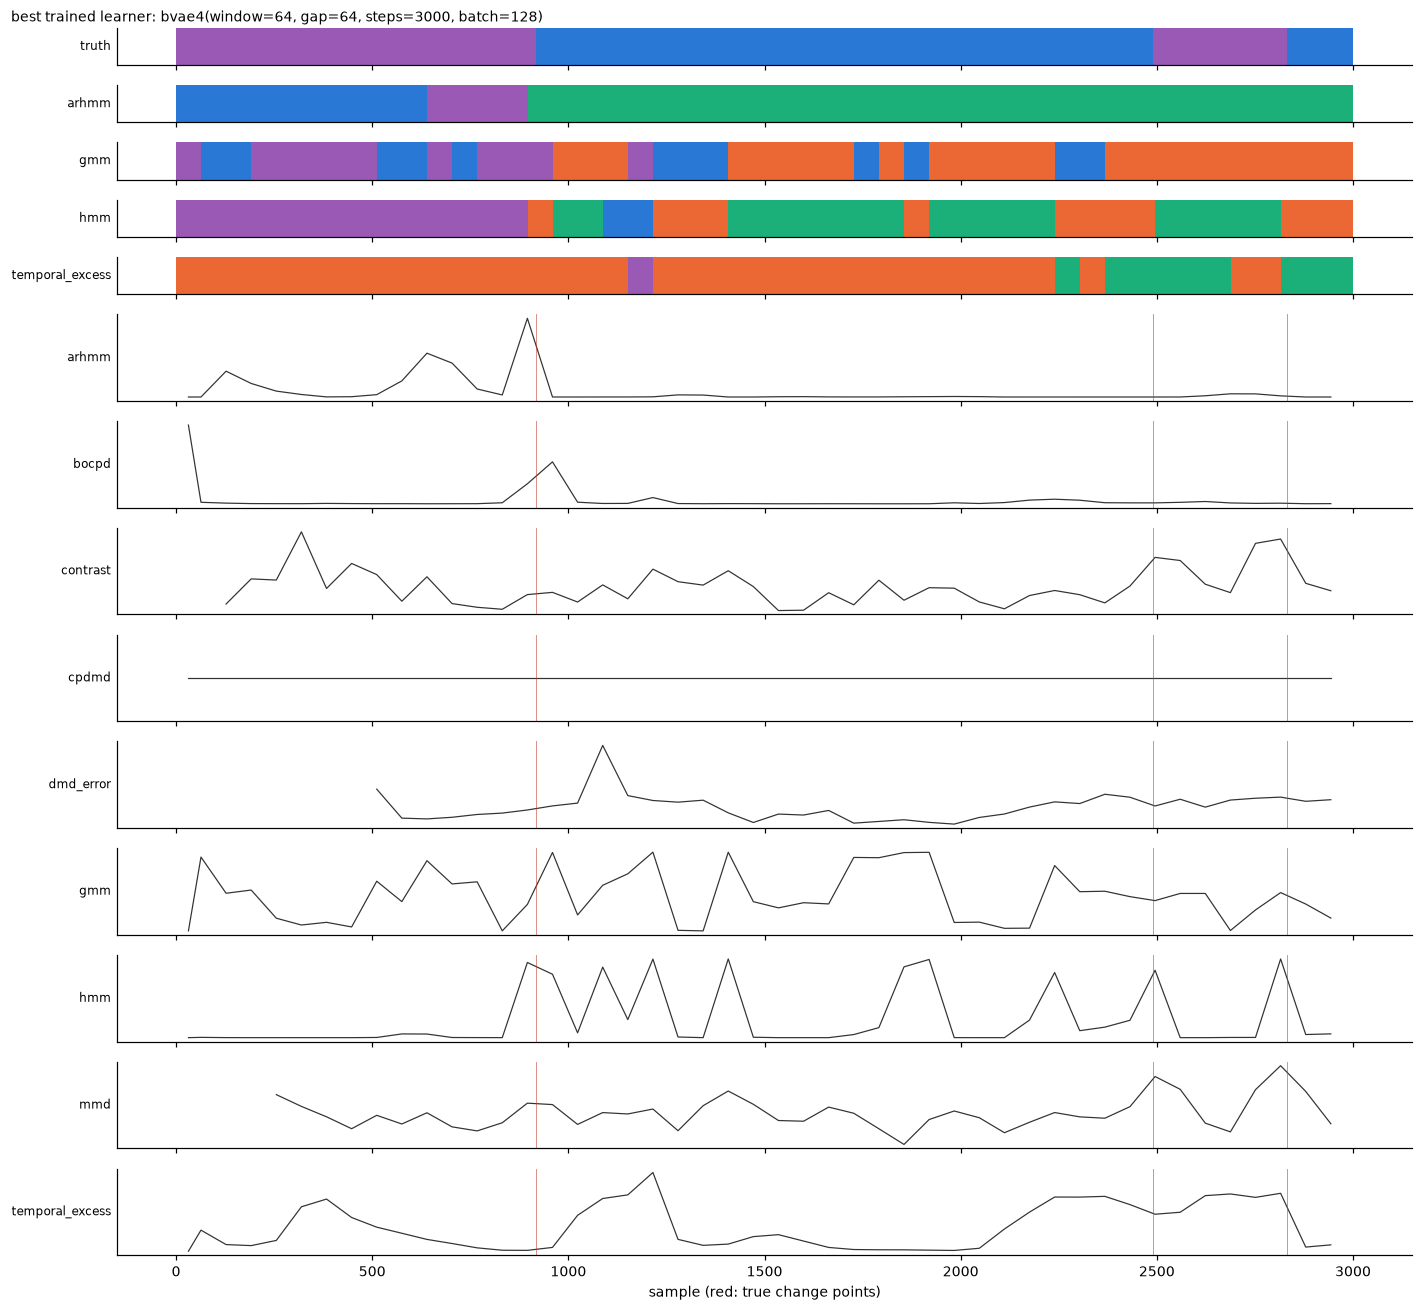

In [13]:
acc = f_[(f_.metric == "acc") & f_.features.isin([f.name for f in LEARNT])].groupby("features_label").value.max()
top = next(f for f in LEARNT if f.label() == acc.idxmax()) if len(acc) else LEARNT[0]
dec, starts = bench.decisions(top)
viz.plot_decisions(data, dec, starts, top.window, ds.K, title=f"best trained learner: {top.label()}", n=3000)

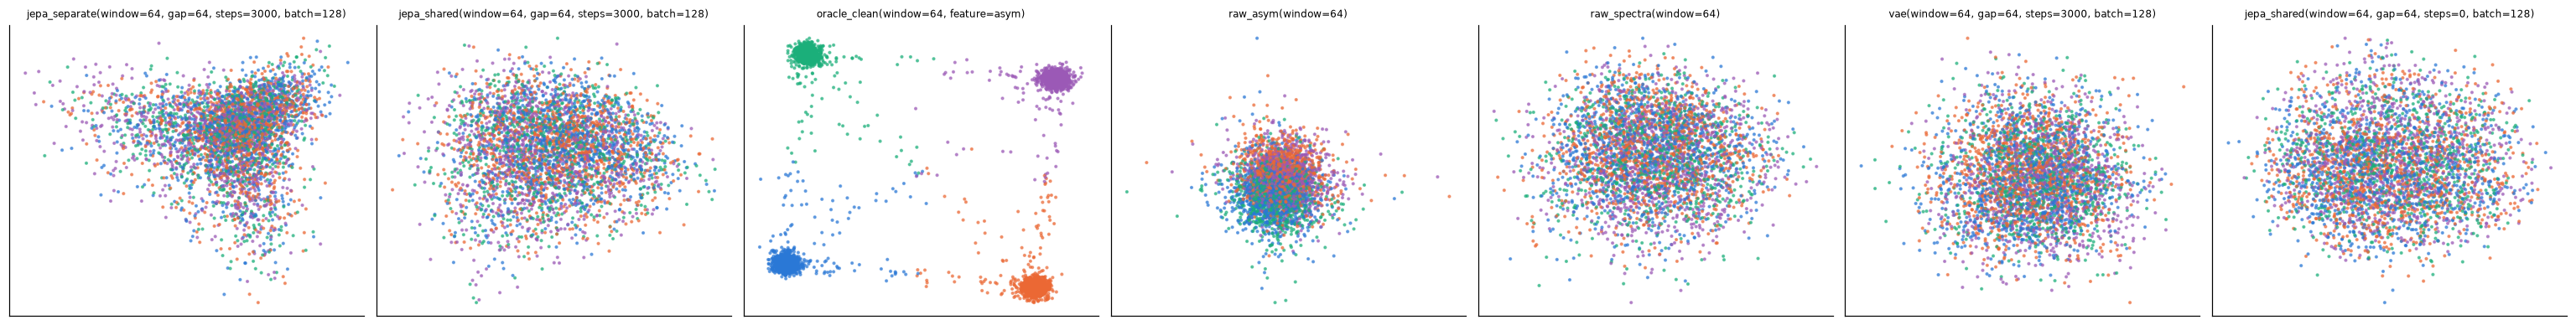

In [14]:
show = [f for f in FEATURES if f.name in ("raw_spectra", "raw_asym", "oracle_clean", "jepa_shared", "jepa_separate", "vae")]
views = {f.label(): bench.features(f)[0]["features"] for f in show}
viz.plot_features(views, data, bench.features(show[0])[1], W, ds.K)

In [15]:
# separate-design JEPAs also expose their target encoder's features: the same detectors on that view
t = res[(res.view == "target") & res.metric.isin(["acc", "cp_ap"])]
if len(t):
    display(t.pivot_table(index="features_label", columns=["metric", "detector_label"], values="value").round(3))

metric                                                          acc                                cp_ap                                                                      
detector_label                                                arhmm    gmm    hmm temporal_excess  arhmm  bocpd contrast  cpdmd dmd_error    gmm    hmm    mmd temporal_excess
features_label                                                                                                                                                                
jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)   0.294  0.286  0.283           0.294  0.275  0.157    0.224  0.015     0.030  0.052  0.058  0.179           0.174
jepa_separate(window=64, gap=64, steps=3000, batch=128)       0.288  0.275  0.272           0.286  0.276  0.165    0.247  0.010     0.028  0.274  0.258  0.219           0.010
jepa_separate_full(window=64, gap=64, steps=3000, batch=128)  0.277  0.286  0.281           0.276  0.254  0.219    0.237  0.011     0.031  0.262  0.271  0.206           0.253